# 1. Data Acquisition.

In [1]:
from data_pipeline import load_snapshot
prices, sectors, vix = load_snapshot()
print(prices.shape, prices.index.min(), prices.index.max())
vix.tail()

(5736, 499) 2004-01-02 00:00:00 2026-10-20 00:00:00


Date
2026-10-14    16.870001
2026-10-15    16.459999
2026-10-16    19.990000
2026-10-19    18.440001
2026-10-20    17.309999
Name: VIX, dtype: float64

# 2. Data Cleaning and Return Calculation

In [2]:
import numpy as np
import pandas as pd

# Align the VIX to stock trading days. ffill carries the last known value forward
# (no look-ahead: a day's VIX is never filled with a later value).
vix = vix.reindex(prices.index).ffill()
print("VIX missing after alignment:", vix.isna().sum())

# Daily returns. fill_method=None means gaps stay NaN instead of being silently filled.
daily_ret = prices.pct_change(fill_method=None)

# Sanity check: the biggest single-day moves (look for obvious data errors)
print(daily_ret.abs().stack().dropna().sort_values().tail(5))

VIX missing after alignment: 0
Date            
2019-01-24  PCG     0.745933
2008-10-29  LVS     0.800000
2008-10-13  MS      0.869835
2008-12-05  HIG     1.023578
2026-08-19  MRNA    1.769695
dtype: float64


# 3. Strategy: signal construction

In [3]:
# Fixed dates, decided in design_choices.md BEFORE looking at results
DEV_START, DEV_END = "2005-01-01", "2017-12-31"
TEST_START = "2018-01-01"   # do NOT use anything from here on until Task 7

# 5-day return ending on each day (uses only prices up to and including that day)
ret5 = prices.pct_change(5, fill_method=None)

# Subtract each stock's sector average that same day -> "sector-adjusted" return
sector_map = sectors.set_index("ticker")["sector"].reindex(prices.columns)
sector_mean = ret5.T.groupby(sector_map).transform("mean").T
signal = ret5 - sector_mean

# Weekly rebalance dates = the last trading day of each week
reb_dates = pd.DatetimeIndex(
    prices.index.to_series().groupby(prices.index.to_period("W")).last().values
)
print(signal.shape, "| weekly dates:", len(reb_dates))
signal.loc[reb_dates].dropna(how="all").iloc[-1].sort_values().head()

(5736, 499) | weekly dates: 1191


SKYD   -0.236050
FLEX   -0.168072
BE     -0.160709
COHR   -0.157758
P      -0.151109
Name: 2026-10-20 00:00:00, dtype: float64

In [4]:
prices.loc['2026-08-17':'2026-08-21', 'MRNA']

Date
2026-08-17     64.459999
2026-08-18     62.959999
2026-08-19    174.380005
2026-08-20    133.320007
2026-08-21    145.130005
Name: MRNA, dtype: float64

# 4. Backtest (development period only: 2005-2017)

In [5]:
def run_reversal(signal, prices, reb_dates, end, cost_bps=5.0, q=0.10, scale=None):
    """Weekly long/short reversal. Signal at close of day t, trade at close of day t+1.
    scale: optional Series (indexed by rebalance date) that multiplies that week's positions."""
    idx = prices.index
    pos = idx.get_indexer(reb_dates)
    assert (pos >= 0).all(), "rebalance date is not a trading day"
    trade_pos = pos + 1                                   # trade ONE day after the signal
    capped = idx[np.minimum(trade_pos, len(idx) - 1)]
    keep = (trade_pos < len(idx)) & (capped <= pd.Timestamp(end))   # never use prices after `end`
    reb_dates, trade_pos = reb_dates[keep], trade_pos[keep]
    trade_dates = idx[trade_pos]
    assert (trade_dates > reb_dates).all(), "look-ahead: trade must be AFTER the signal date"
    if scale is not None:
        assert scale.reindex(reb_dates[:-1]).notna().all(), "scale missing for a rebalance date"

    w_prev = pd.Series(0.0, index=prices.columns)
    rows = []
    for k in range(len(reb_dates) - 1):
        s = signal.loc[reb_dates[k]]
        s = s[s.notna() & prices.iloc[trade_pos[k]].notna()]   # only stocks tradable on the trade date
        n = int(len(s) * q)                                    # decile size
        assert n >= 5, f"too few stocks on {reb_dates[k]}"
        w = pd.Series(0.0, index=prices.columns)
        w[s.nsmallest(n).index] = 1.0 / n                      # long the biggest losers vs sector
        w[s.nlargest(n).index] = -1.0 / n                      # short the biggest winners vs sector
        assert abs(w.sum()) < 1e-9                             # dollar-neutral
        m = 1.0 if scale is None else float(scale.loc[reb_dates[k]])
        w = w * m                                              # scaled positions (m = 1 means unconditional)
        r = (prices.iloc[trade_pos[k + 1]] / prices.iloc[trade_pos[k]] - 1).fillna(0.0)
        gross = float((w * r).sum())
        turnover = float((w - w_prev).abs().sum())             # dollars traded (both sides)
        cost = turnover * cost_bps / 1e4
        rows.append((trade_dates[k + 1], gross, cost, gross - cost, n, turnover, m))
        w_prev = w
    cols = ["end_date", "gross", "cost", "net", "n_per_side", "turnover", "scale"]
    return pd.DataFrame(rows, columns=cols).set_index("end_date")

def perf(r, periods=52):
    r = r.dropna()
    wealth = (1 + r).cumprod()
    ann_ret, ann_vol = r.mean() * periods, r.std() * np.sqrt(periods)
    return pd.Series({"cum_return": wealth.iloc[-1] - 1, "ann_return": ann_ret,
                      "ann_vol": ann_vol, "sharpe": ann_ret / ann_vol,
                      "max_drawdown": (wealth / wealth.cummax() - 1).min(), "weeks": len(r)})

In [6]:
dev_reb = reb_dates[(reb_dates >= DEV_START) & (reb_dates <= DEV_END)]

res5  = run_reversal(signal, prices, dev_reb, end=DEV_END, cost_bps=5)
res10 = run_reversal(signal, prices, dev_reb, end=DEV_END, cost_bps=10)

results = pd.DataFrame({
    "gross (no costs)": perf(res5["gross"]),
    "net, 5 bps":       perf(res5["net"]),
    "net, 10 bps":      perf(res10["net"]),
})
print(results.round(3))
print("avg stocks per side:", round(res5["n_per_side"].mean(), 1),
      "| avg weekly turnover:", round(res5["turnover"].mean(), 2))

              gross (no costs)  net, 5 bps  net, 10 bps
cum_return               3.337       0.380       -0.562
ann_return               0.124       0.036       -0.052
ann_vol                  0.152       0.152        0.152
sharpe                   0.816       0.237       -0.342
max_drawdown            -0.205      -0.244       -0.620
weeks                  676.000     676.000      676.000
avg stocks per side: 42.6 | avg weekly turnover: 3.39


# 5. Mechanism test: does reversal pay more after high VIX? (development period only)

In [7]:
import statsmodels.api as sm

# VIX percentile: where today's VIX ranks among ALL past values (expanding window, no look-ahead)
vix_pct = vix.expanding(min_periods=250).apply(lambda x: (x <= x[-1]).mean(), raw=True)

# Signal date for each weekly return (VIX is read on the signal date, BEFORE the holding period)
sig_dates = dev_reb[:len(res5)]
exp_end = prices.index[prices.index.get_indexer(dev_reb[1:len(res5) + 1]) + 1]
assert (exp_end == res5.index).all(), "signal dates and return dates are misaligned"
assert (sig_dates < res5.index).all()

d = pd.DataFrame({"gross": res5["gross"].values,
                  "vix_pct": vix_pct.loc[sig_dates].values}, index=res5.index).dropna()

# Regression with Newey-West (HAC) standard errors
X = sm.add_constant(d["vix_pct"])
fit = sm.OLS(d["gross"], X).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
print(fit.summary().tables[1])

# Simple view: average weekly gross return in low / mid / high VIX terciles
d["bucket"] = pd.cut(d["vix_pct"], [0, 1/3, 2/3, 1.0],
                     labels=["low VIX", "mid VIX", "high VIX"], include_lowest=True)
tab = d.groupby("bucket", observed=True)["gross"].agg(weeks="count", mean_weekly="mean", std_weekly="std")
tab["ann_return"] = tab["mean_weekly"] * 52
print(tab.round(4))

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0001      0.001     -0.119      0.905      -0.002       0.002
vix_pct        0.0053      0.003      1.625      0.104      -0.001       0.012
          weeks  mean_weekly  std_weekly  ann_return
bucket                                              
low VIX     260       0.0012      0.0101      0.0613
mid VIX     197       0.0008      0.0123      0.0424
high VIX    219       0.0052      0.0333      0.2726


# 6. Conditional allocation rule (development period only: 2005-2017)

In [8]:
def expanding_pct(x, min_periods=250):
    """Percentile of today's value within all values seen up to today (no future data)."""
    return x.expanding(min_periods=min_periods).apply(lambda v: (v <= v[-1]).mean(), raw=True)

# Benchmark: same rule but driven by REALISED market volatility instead of VIX
mkt = daily_ret.mean(axis=1)                                   # equal-weighted average stock return
rv = mkt.rolling(21).std() * np.sqrt(252)                      # trailing 21-day realised vol
rv_pct = expanding_pct(rv.dropna()).reindex(prices.index)

def make_scale(pct, dates, lo=0.5, hi=1.5):
    """Position multiplier: 0.5 when volatility is at its lowest, 1.5 at its highest."""
    return (lo + (hi - lo) * pct.reindex(dates)).clip(lo, hi).fillna(1.0)   # neutral 1.0 until 250 days of history

s_vix = make_scale(vix_pct, dev_reb)                           # vix_pct comes from the mechanism-test cell
s_rv  = make_scale(rv_pct,  dev_reb)

tables = {}
for bps in (5, 10):
    base = run_reversal(signal, prices, dev_reb, DEV_END, cost_bps=bps)
    cond = run_reversal(signal, prices, dev_reb, DEV_END, cost_bps=bps, scale=s_vix)
    rvol = run_reversal(signal, prices, dev_reb, DEV_END, cost_bps=bps, scale=s_rv)
    tables[bps] = (base, cond, rvol)
    print(f"--- net of {bps} bps per side ---")
    print(pd.DataFrame({"unconditional": perf(base["net"]),
                        "VIX rule": perf(cond["net"]),
                        "realised-vol rule": perf(rvol["net"])}).round(3))

base, cond, rvol = tables[5]
print("\naverage multiplier  VIX rule:", round(cond["scale"].mean(), 2),
      "| realised-vol rule:", round(rvol["scale"].mean(), 2))

# Is the VIX-rule improvement over unconditional distinguishable from noise? (HAC t-stat, 5 bps)
diff = cond["net"] - base["net"]
fit = sm.OLS(diff.values, np.ones(len(diff))).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
print("mean weekly gain from VIX rule:", round(diff.mean(), 5),
      "| annualised:", round(diff.mean() * 52, 4), "| t-stat:", round(float(fit.tvalues[0]), 2))

--- net of 5 bps per side ---
              unconditional  VIX rule  realised-vol rule
cum_return            0.380     0.721              0.698
ann_return            0.036     0.062              0.061
ann_vol               0.152     0.205              0.203
sharpe                0.237     0.302              0.298
max_drawdown         -0.244    -0.329             -0.328
weeks               676.000   676.000            676.000
--- net of 10 bps per side ---
              unconditional  VIX rule  realised-vol rule
cum_return           -0.562    -0.443             -0.450
ann_return           -0.052    -0.025             -0.026
ann_vol               0.152     0.205              0.203
sharpe               -0.342    -0.121             -0.128
max_drawdown         -0.620    -0.588             -0.591
weeks               676.000   676.000            676.000

average multiplier  VIX rule: 0.98 | realised-vol rule: 0.97
mean weekly gain from VIX rule: 0.0005 | annualised: 0.0259 | t-stat: 1.57


# 7. Out-of-sample test (2018 to Oct 2026): run once, rules frozen

In [9]:
import os

test_reb = reb_dates[reb_dates >= TEST_START]
END_ALL = prices.index[-1]

# Same rules as development: multipliers use only data up to each signal date
s_vix_t = make_scale(vix_pct, test_reb)
s_rv_t  = make_scale(rv_pct,  test_reb)

test_tables, summary = {}, {}
for bps in (5, 10):
    u = run_reversal(signal, prices, test_reb, END_ALL, cost_bps=bps)
    v = run_reversal(signal, prices, test_reb, END_ALL, cost_bps=bps, scale=s_vix_t)
    r = run_reversal(signal, prices, test_reb, END_ALL, cost_bps=bps, scale=s_rv_t)
    test_tables[bps] = (u, v, r)
    summary[bps] = pd.DataFrame({"unconditional": perf(u["net"]),
                                 "VIX rule": perf(v["net"]),
                                 "realised-vol rule": perf(r["net"])}).round(3)
    print(f"--- TEST period, net of {bps} bps per side ---")
    print(summary[bps])

u5, v5, r5 = test_tables[5]
print("\naverage multiplier  VIX rule:", round(v5["scale"].mean(), 2),
      "| realised-vol rule:", round(r5["scale"].mean(), 2))
diff = v5["net"] - u5["net"]
fit = sm.OLS(diff.values, np.ones(len(diff))).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
print("mean weekly gain from VIX rule:", round(diff.mean(), 5),
      "| annualised:", round(diff.mean() * 52, 4), "| t-stat:", round(float(fit.tvalues[0]), 2))

# Mechanism check on the test period: is the gross reversal return higher after high VIX?
sig_dates = test_reb[:len(u5)]
assert len(sig_dates) == len(u5) and (u5.index > sig_dates).all()
assert u5.index.min() > pd.Timestamp(DEV_END)
d_test = pd.DataFrame({"gross": u5["gross"].values, "vix_pct": vix_pct.reindex(sig_dates).values})
fit2 = sm.OLS(d_test["gross"], sm.add_constant(d_test["vix_pct"])).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
print("\nslope of weekly gross return on lagged VIX percentile:", round(fit2.params["vix_pct"], 5),
      "| t-stat:", round(fit2.tvalues["vix_pct"], 2))
print(d_test.groupby(pd.cut(d_test["vix_pct"], [0, 1/3, 2/3, 1.0]), observed=True)["gross"].agg(["mean", "count"]).round(5))

os.makedirs("results", exist_ok=True)
pd.concat(summary, names=["cost_bps"]).to_csv("results/test_results.csv")

--- TEST period, net of 5 bps per side ---
              unconditional  VIX rule  realised-vol rule
cum_return           -0.521    -0.478             -0.353
ann_return           -0.069    -0.051             -0.029
ann_vol               0.173     0.217              0.205
sharpe               -0.397    -0.233             -0.140
max_drawdown         -0.690    -0.704             -0.654
weeks               458.000   458.000            458.000
--- TEST period, net of 10 bps per side ---
              unconditional  VIX rule  realised-vol rule
cum_return           -0.780    -0.774             -0.706
ann_return           -0.157    -0.145             -0.118
ann_vol               0.173     0.217              0.205
sharpe               -0.906    -0.670             -0.577
max_drawdown         -0.824    -0.841             -0.806
weeks               458.000   458.000            458.000

average multiplier  VIX rule: 1.07 | realised-vol rule: 1.01
mean weekly gain from VIX rule: 0.00035 | annualised:

In [10]:
print("TEST period, GROSS (before costs), unconditional strategy:")
print(perf(u5["gross"]).round(3))

TEST period, GROSS (before costs), unconditional strategy:
cum_return        0.042
ann_return        0.020
ann_vol           0.173
sharpe            0.113
max_drawdown     -0.461
weeks           458.000
dtype: float64


# 8. Figure and sector-exposure diagnostic

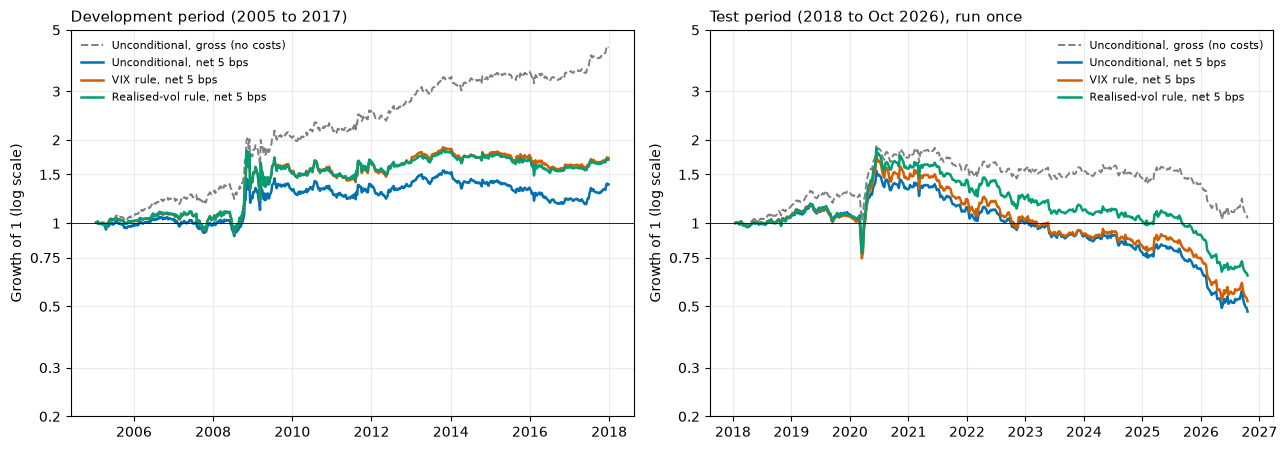

In [11]:
import os
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

def wealth(r):
    return (1 + r.dropna()).cumprod()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
panels = [("Development period (2005 to 2017)", tables[5]),
          ("Test period (2018 to Oct 2026), run once", test_tables[5])]
for ax, (title, (u_, v_, r_)) in zip(axes, panels):
    ax.plot(wealth(u_["gross"]), color="#7F7F7F", lw=1.4, ls="--", label="Unconditional, gross (no costs)")
    ax.plot(wealth(u_["net"]),   color="#0072B2", lw=1.8, label="Unconditional, net 5 bps")
    ax.plot(wealth(v_["net"]),   color="#D55E00", lw=1.8, label="VIX rule, net 5 bps")
    ax.plot(wealth(r_["net"]),   color="#009E73", lw=1.8, label="Realised-vol rule, net 5 bps")
    ax.axhline(1.0, color="black", lw=0.6)
    ax.set_yscale("log")
    ax.set_yticks([0.2, 0.3, 0.5, 0.75, 1, 1.5, 2, 3, 5]); ax.set_yticks([], minor=True)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
    ax.set_title(title, fontsize=11, loc="left")
    ax.set_ylabel("Growth of 1 (log scale)")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8, loc="best", frameon=False)
fig.tight_layout()
os.makedirs("results", exist_ok=True)
fig.savefig("results/equity_curves.png", dpi=150)
plt.show()

In [12]:
def sector_exposure(signal, prices, reb_dates, end, q=0.10):
    """Net and long-leg weight per GICS sector at each rebalance (same selection rule as run_reversal)."""
    idx = prices.index
    pos = idx.get_indexer(reb_dates)
    trade_pos = pos + 1
    keep = (trade_pos < len(idx)) & (idx[np.minimum(trade_pos, len(idx) - 1)] <= pd.Timestamp(end))
    reb_dates, trade_pos = reb_dates[keep], trade_pos[keep]
    net_rows, long_rows = [], []
    for k in range(len(reb_dates) - 1):
        s = signal.loc[reb_dates[k]]
        s = s[s.notna() & prices.iloc[trade_pos[k]].notna()]
        n = int(len(s) * q)
        w = pd.Series(0.0, index=s.index)
        w[s.nsmallest(n).index] = 1.0 / n
        w[s.nlargest(n).index] = -1.0 / n
        sec = sector_map.reindex(s.index)
        net_rows.append(w.groupby(sec).sum())
        long_rows.append(w.clip(lower=0).groupby(sec).sum())
    return pd.DataFrame(net_rows).fillna(0.0), pd.DataFrame(long_rows).fillna(0.0)

net_sec, long_sec = sector_exposure(signal, prices, dev_reb, DEV_END)
assert len(net_sec) == len(tables[5][0]) and (net_sec.sum(axis=1).abs() < 1e-9).all()
summary_sec = pd.DataFrame({"mean net": net_sec.mean(), "mean |net|": net_sec.abs().mean(),
                            "max |net|": net_sec.abs().max()}).round(3)
print(summary_sec.sort_values("mean |net|", ascending=False))
print("\nAverage total |net| sector exposure (sum over sectors, 1.0 = one leg):",
      round(net_sec.abs().sum(axis=1).mean(), 3))
print("Largest single-sector share of the long leg (average over weeks):",
      round(long_sec.max(axis=1).mean(), 3))

                        mean net  mean |net|  max |net|
sector                                                 
Information Technology     0.002       0.043      0.170
Financials                -0.002       0.042      0.341
Industrials               -0.005       0.040      0.146
Health Care                0.001       0.037      0.239
Consumer Discretionary     0.005       0.036      0.191
Consumer Staples          -0.001       0.026      0.143
Materials                  0.000       0.025      0.133
Real Estate               -0.001       0.025      0.132
Communication Services     0.002       0.022      0.250
Energy                    -0.000       0.020      0.130
Utilities                 -0.002       0.018      0.079

Average total |net| sector exposure (sum over sectors, 1.0 = one leg): 0.332
Largest single-sector share of the long leg (average over weeks): 0.23


In [13]:
import time
t = time.time(); _ = expanding_pct(vix); print("expanding percentile:", round(time.time() - t, 2), "s")
t = time.time(); _ = run_reversal(signal, prices, dev_reb, DEV_END); print("one backtest:", round(time.time() - t, 2), "s")

expanding percentile: 0.04 s
one backtest: 1.24 s
